# 06 — Public-data conditioning

**Portfolio / learning project — not a calibrated instrument simulator or ETC.** This notebook shows how cached *public* data (SVO filters, ESO SkyCalc sky/telluric, CALSPEC source) enters the physical chain of the `public_conditioned` mode: filter throughput, telluric absorption, source continuum shape, and a sky-background electron contribution. The sky/filter scalings are physically motivated but their absolute level is an `engineering_estimate`, **not** an observatory-grade ETC.

Runs offline from `data/public_cache/` (populated by `examples/fetch_public_data.py`); if the cache is absent, the loaders fall back to synthetic proxies and provenance flips.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
import numpy as np, matplotlib.pyplot as plt, pandas as pd, tempfile
from ao_fed_ifu.data_sources import load_filter_curve, load_sky_spectrum, load_source_spectrum
from ao_fed_ifu.integration import make_public_conditioned_config, run_pipeline
FIG = pathlib.Path.cwd().parent / 'figures' / 'notebooks'


## 1. The public inputs
Load the cached curves and check their provenance. `direct_public_data` means a real cached file was read; `synthetic_proxy` means the documented fallback was used.

filter_K : direct_public_data
sky      : direct_public_data
source   : direct_public_data


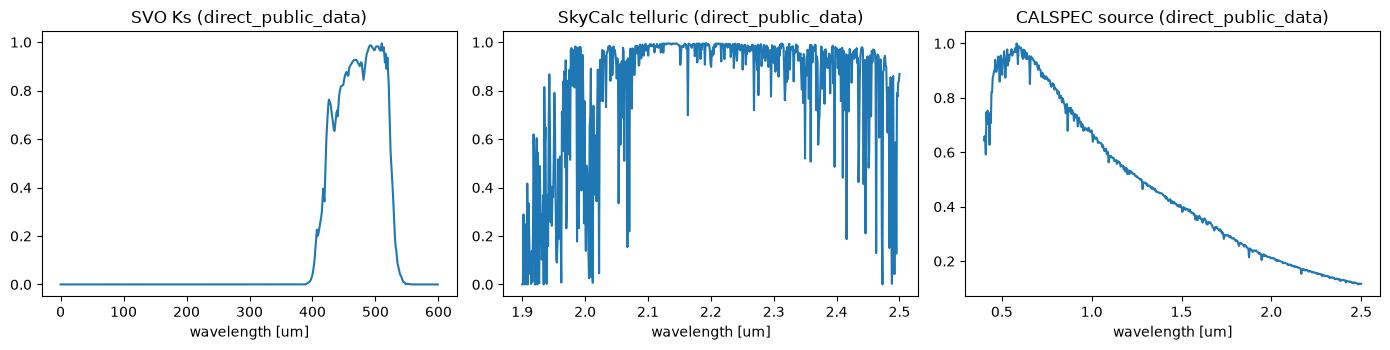

In [2]:
wl_f = np.linspace(0.9, 2.5, 600); wl_s = np.linspace(1.9, 2.5, 600); wl_src = np.linspace(0.4, 2.5, 600)
fK, pK = load_filter_curve('K'); sky, pS = load_sky_spectrum(wl_s); src, pSrc = load_source_spectrum(wl_src)
print('filter_K :', pK.source_class); print('sky      :', pS.source_class); print('source   :', pSrc.source_class)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(np.interp(wl_f, fK['wavelength_um'], fK['transmission'], left=0, right=0)); ax[0].set_title(f'SVO Ks ({pK.source_class})')
ax[1].plot(wl_s, sky['transmission']); ax[1].set_title(f'SkyCalc telluric ({pS.source_class})')
ax[2].plot(wl_src, src['flux']); ax[2].set_title(f'CALSPEC source ({pSrc.source_class})')
for a in ax: a.set_xlabel('wavelength [um]')
fig.tight_layout(); plt.show()

## 2. Public-conditioned vs synthetic fallback
Run the **same** pipeline twice: once reading the real cache, once forced onto the synthetic fallback by pointing the loaders at an empty directory. Compare the budget metrics.

In [3]:
cfg = make_public_conditioned_config(nx=14, ny=14, resolving_power_R=2500.0)
pub = run_pipeline(cfg)
with tempfile.TemporaryDirectory() as d:
    syn = run_pipeline(make_public_conditioned_config(nx=14, ny=14, resolving_power_R=2500.0, public_cache_dir=d))
keys = ['filter_weighted_throughput','sky_to_source_ratio','source_electrons','sky_background_electrons','median_snr','public_data_components_used']
pd.DataFrame({'metric': keys, 'public': [pub.metrics[k] for k in keys], 'synthetic': [syn.metrics[k] for k in keys]})

,metric,public,synthetic
0,filter_weighted_throughput,5.487238e-01,9.170107e-01
1,sky_to_source_ratio,2.945266e-01,1.213641e-01
2,source_electrons,1.353215e+07,2.298210e+07
3,sky_background_electrons,3.985577e+06,2.789200e+06
4,median_snr,3.988681e+01,3.853765e+01
5,public_data_components_used,3.000000e+00,0.000000e+00


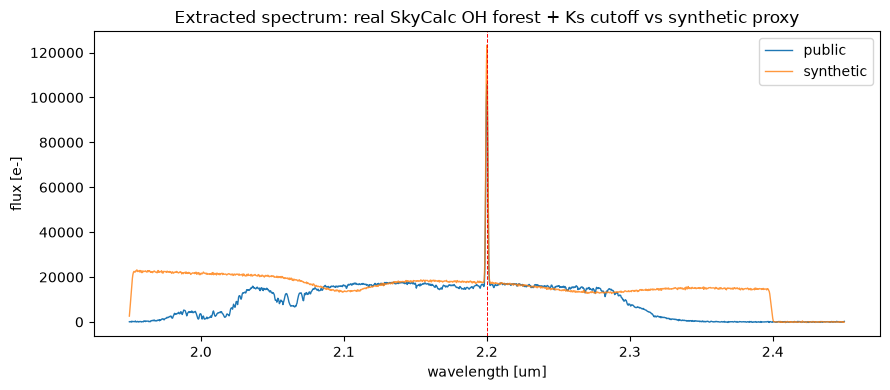

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(pub.wavelength_grid_um, pub.extracted_spectrum, label='public', lw=1.0)
ax.plot(syn.wavelength_grid_um, syn.extracted_spectrum, label='synthetic', lw=1.0, alpha=0.8)
ax.axvline(pub.line_center_um, color='r', ls='--', lw=0.7); ax.legend()
ax.set_title('Extracted spectrum: real SkyCalc OH forest + Ks cutoff vs synthetic proxy')
ax.set_xlabel('wavelength [um]'); ax.set_ylabel('flux [e-]'); fig.tight_layout(); plt.show()

## 3. Sky background and SNR
The SkyCalc radiance is converted to a sky-background electron contribution per spaxel per wavelength bin and added to the detector budget (engineering-estimate scaling). The `sky_to_source_ratio` and the sky spectrum below show the regime; fine spaxels see little sky per spaxel.

source electrons     : 1.353e+07
sky background e-     : 3.986e+06
sky / source ratio   : 0.295


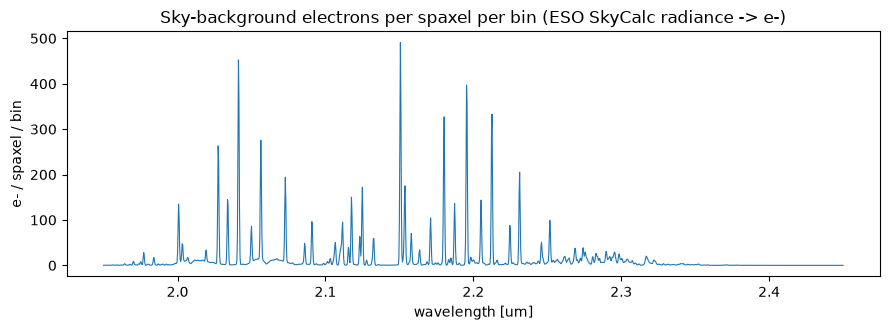

In [5]:
print('source electrons     :', f"{pub.metrics['source_electrons']:.3e}")
print('sky background e-     :', f"{pub.metrics['sky_background_electrons']:.3e}")
print('sky / source ratio   :', f"{pub.metrics['sky_to_source_ratio']:.3f}")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(pub.wavelength_grid_um, pub.sky_background_spectrum, lw=0.8)
ax.set_title('Sky-background electrons per spaxel per bin (ESO SkyCalc radiance -> e-)')
ax.set_xlabel('wavelength [um]'); ax.set_ylabel('e- / spaxel / bin'); fig.tight_layout(); plt.show()

## Provenance
Every conditioning input keeps an honest provenance label; the budget metrics are derived engineering estimates. This is a reproducible technical demonstration, not a performance claim for any real instrument.

In [6]:
print('provenance counts:', pub.provenance.summary_counts())
print('components       :', pub.conditioning_info['components'])
for r in pub.provenance.records:
    if r.name in ('sky_spectrum','source_spectrum','filter_K','filter_throughput','sky_background'):
        print(f'  {r.name:16s} {r.source_class:20s} {r.url_or_reference[:55]}')

provenance counts: {'direct_public_data': 4, 'literature_derived': 3, 'engineering_estimate': 4, 'synthetic_proxy': 3, 'internal_validation': 0}
components       : {'sky_spectrum': 'direct_public_data', 'source_spectrum': 'direct_public_data', 'filter_K': 'direct_public_data'}
  sky_spectrum     direct_public_data   local cache data/public_cache/skycalc.dat
  source_spectrum  direct_public_data   local cache data/public_cache/source.dat
  filter_K         direct_public_data   local cache data/public_cache/K.dat
  filter_throughput direct_public_data   SVO 2MASS Ks transmission as a wavelength-dependent ban
  sky_background   engineering_estimate native sky * filter -> spectral LSF -> detector-bin int
